In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

BASE_PATH = "/content/drive/MyDrive/ML_lab"
CSV_PATH = os.path.join(BASE_PATH, "BreaKHis_metadata.csv")
IMAGE_ROOT = os.path.join(BASE_PATH, "BreaKHis_v1")

IMAGE_SIZE = (16, 16)
SAMPLES_PER_CLASS = 100
RANDOM_STATE = 42

LEARNING_RATE = 0.05
MAX_EPOCHS = 1000
CONVERGENCE_ERROR = 0.002

In [ ]:
drive.mount("/content/drive")

metadata = pd.read_csv(CSV_PATH)

metadata["label"] = metadata["filename"].apply(
    lambda path: (
        "benign" if "/benign/" in str(path).lower()
        else "malignant" if "/malignant/" in str(path).lower()
        else None
    )
)

metadata = metadata.dropna(subset=["label"]).reset_index(drop=True)

print("Metadata shape:", metadata.shape)
print("\nAvailable images:")
print(metadata["label"].value_counts())

Mounted at /content/drive
Metadata shape: (39545, 5)

Available images:
label
malignant    27145
benign       12400
Name: count, dtype: int64


In [ ]:
def locate_image(filename):
    relative_path = str(filename).replace("\\", "/").lstrip("/")

    candidates = [
        os.path.join(BASE_PATH, relative_path),
        os.path.join(IMAGE_ROOT, relative_path)
    ]

    if relative_path.startswith("BreaKHis_v1/"):
        short_path = relative_path.split("BreaKHis_v1/", 1)[1]
        candidates.extend([
            os.path.join(IMAGE_ROOT, short_path),
            os.path.join(IMAGE_ROOT, "BreaKHis_v1", short_path)
        ])

    for candidate in candidates:
        if os.path.isfile(candidate):
            return candidate

    return None


def load_project_dataset(dataframe):
    features = []
    labels = []
    missing_files = 0

    for _, row in dataframe.iterrows():
        image_path = locate_image(row["filename"])

        if image_path is None:
            missing_files += 1
            continue

        try:
            with Image.open(image_path) as image:
                image = image.convert("L")
                image = image.resize(IMAGE_SIZE)
                image_array = np.asarray(image, dtype=np.float32) / 255.0

            features.append(image_array.flatten())
            labels.append(1 if row["label"] == "malignant" else 0)

        except (OSError, ValueError):
            missing_files += 1

    X = np.asarray(features, dtype=np.float32).reshape(-1, 256)
    y = np.asarray(labels, dtype=np.int64)

    return X, y, missing_files

In [ ]:
# A1 functions
def summation_unit(inputs, weights):
    inputs = np.asarray(inputs, dtype=float)
    weights = np.asarray(weights, dtype=float)

    if len(weights) != len(inputs) + 1:
        raise ValueError("Weights must contain one bias and one weight per input.")

    return weights[0] + np.dot(weights[1:], inputs)


def step_activation(value):
    return 1 if value >= 0 else 0


def bipolar_step_activation(value):
    if value > 0:
        return 1
    elif value < 0:
        return -1
    return 0


def sigmoid_activation(value):
    value = np.clip(value, -500, 500)
    return 1 / (1 + np.exp(-value))


def tanh_activation(value):
    return np.tanh(value)


def relu_activation(value):
    return max(0, value)


def leaky_relu_activation(value, alpha=0.01):
    return value if value >= 0 else alpha * value


def error_comparator(target, output):
    return np.asarray(target, dtype=float) - np.asarray(output, dtype=float)

In [ ]:
# A2 Functions
def train_perceptron_and(
    learning_rate=0.05,
    max_epochs=1000,
    convergence_error=0.002
):
    X = np.array([
        [0, 0],
        [0, 1],
        [1, 0],
        [1, 1]
    ], dtype=float)

    y = np.array([0, 0, 0, 1])

    weights = np.array([10.0, 0.2, -0.75])
    errors_per_epoch = []

    for epoch in range(1, max_epochs + 1):
        for inputs, target in zip(X, y):
            net_input = summation_unit(inputs, weights)
            prediction = step_activation(net_input)
            error = target - prediction

            weights[0] += learning_rate * error
            weights[1:] += learning_rate * error * inputs

        predictions = np.array([
            step_activation(summation_unit(inputs, weights))
            for inputs in X
        ])

        errors = error_comparator(y, predictions)
        sse = float(np.sum(errors ** 2))
        errors_per_epoch.append(sse)

        if sse <= convergence_error:
            break

    return weights, epoch, errors_per_epoch, X, y

In [ ]:
#A3 Func

def train_perceptron_activation(
    X,
    y,
    activation,
    learning_rate=0.05,
    max_epochs=1000,
    convergence_error=0.002
):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)

    weights = np.array([10.0, 0.2, -0.75])
    errors_per_epoch = []

    for epoch in range(1, max_epochs + 1):
        for inputs, target in zip(X, y):
            net_input = summation_unit(inputs, weights)
            output = activation(net_input)
            error = target - output

            weights[0] += learning_rate * error
            weights[1:] += learning_rate * error * inputs

        predictions = np.array([
            activation(summation_unit(inputs, weights))
            for inputs in X
        ])

        sse = float(np.sum((y - predictions) ** 2))
        errors_per_epoch.append(sse)

        if sse <= convergence_error:
            break

    return weights, epoch, errors_per_epoch, X, y

In [ ]:
# A4 Func

def compare_learning_rates(
    X,
    y,
    learning_rates=np.arange(0.1, 1.01, 0.1),
    max_epochs=1000,
    convergence_error=0.002
):
    results = []

    for learning_rate in learning_rates:
        weights = np.array([10.0, 0.2, -0.75])
        errors_per_epoch = []

        for epoch in range(1, max_epochs + 1):
            for inputs, target in zip(X, y):
                net_input = summation_unit(inputs, weights)
                prediction = step_activation(net_input)
                error = target - prediction

                weights[0] += learning_rate * error
                weights[1:] += learning_rate * error * inputs

            predictions = np.array([
                step_activation(summation_unit(inputs, weights))
                for inputs in X
            ])

            sse = float(np.sum((y - predictions) ** 2))
            errors_per_epoch.append(sse)

            if sse <= convergence_error:
                break

        results.append({
            "Learning Rate": round(float(learning_rate), 1),
            "Iterations": epoch,
            "Final SSE": errors_per_epoch[-1],
            "Converged": errors_per_epoch[-1] <= convergence_error
        })

    return pd.DataFrame(results)

In [ ]:
# A5 Func

def get_xor_dataset():
    X_xor = np.array([
        [0, 0],
        [0, 1],
        [1, 0],
        [1, 1]
    ], dtype=float)

    y_xor = np.array([0, 1, 1, 0])

    return X_xor, y_xor

In [ ]:
# A6 Func

def train_customer_perceptron(learning_rate=0.1, max_epochs=10000):
    X = np.array([
        [20, 6, 2, 386],
        [16, 3, 6, 289],
        [27, 6, 2, 393],
        [19, 1, 2, 110],
        [24, 4, 2, 280],
        [22, 1, 5, 167],
        [15, 4, 2, 271],
        [18, 4, 2, 274],
        [21, 1, 4, 148],
        [16, 2, 4, 198]
    ], dtype=float)

    y = np.array([1, 1, 1, 0, 1, 0, 1, 1, 0, 0], dtype=float)

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    weights = np.zeros(X_scaled.shape[1] + 1)
    errors_per_epoch = []

    for epoch in range(1, max_epochs + 1):
        squared_errors = []

        for inputs, target in zip(X_scaled, y):
            net_input = summation_unit(inputs, weights)
            output = sigmoid_activation(net_input)
            error = target - output

            delta = error * output * (1 - output)

            weights[0] += learning_rate * delta
            weights[1:] += learning_rate * delta * inputs

            squared_errors.append(error ** 2)

        errors_per_epoch.append(float(np.mean(squared_errors)))

    outputs = np.array([
        sigmoid_activation(summation_unit(inputs, weights))
        for inputs in X_scaled
    ])

    predictions = (outputs >= 0.5).astype(int)

    return X, y, outputs, predictions, weights, scaler, errors_per_epoch, epoch

In [ ]:
#A7 Func

def compare_pseudoinverse(X, y):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    X_bias = np.column_stack([
        np.ones(X_scaled.shape[0]),
        X_scaled
    ])

    weights = np.linalg.pinv(X_bias) @ y

    outputs = X_bias @ weights
    predictions = (outputs >= 0.5).astype(int)

    return weights, outputs, predictions

In [ ]:
# A8 Func

def train_and_backpropagation(
    learning_rate=0.05,
    max_epochs=1000,
    convergence_error=0.002
):
    X = np.array([
        [0, 0],
        [0, 1],
        [1, 0],
        [1, 1]
    ], dtype=float)

    y = np.array([[0], [0], [0], [1]], dtype=float)

    rng = np.random.default_rng(42)
    hidden_weights = rng.uniform(-0.5, 0.5, (2, 3))
    output_weights = rng.uniform(-0.5, 0.5, (1, 3))

    errors_per_epoch = []

    for epoch in range(1, max_epochs + 1):
        for inputs, target in zip(X, y):
            inputs_bias = np.append(inputs, 1.0)

            hidden_net = hidden_weights @ inputs_bias
            hidden_output = sigmoid_activation(hidden_net)

            hidden_bias = np.append(hidden_output, 1.0)
            output_net = output_weights @ hidden_bias
            output = sigmoid_activation(output_net[0])

            output_delta = (target[0] - output) * output * (1 - output)

            hidden_delta = (
                output_weights[0, :2]
                * output_delta
                * hidden_output
                * (1 - hidden_output)
            )

            output_weights[0] += learning_rate * output_delta * hidden_bias
            hidden_weights += learning_rate * np.outer(
                hidden_delta, inputs_bias
            )

        hidden_outputs = np.array([
            sigmoid_activation(hidden_weights @ np.append(inputs, 1.0))
            for inputs in X
        ])

        predictions = np.array([
            sigmoid_activation(
                output_weights @ np.append(hidden_output, 1.0)
            )[0]
            for hidden_output in hidden_outputs
        ])

        sse = float(np.sum((y.flatten() - predictions) ** 2))
        errors_per_epoch.append(sse)

        if sse <= convergence_error:
            break

    return (
        hidden_weights,
        output_weights,
        epoch,
        errors_per_epoch,
        X,
        y.flatten(),
        predictions
    )

In [ ]:
# A9 Func

def train_xor_backpropagation(
    learning_rate=0.05,
    max_epochs=1000,
    convergence_error=0.002
):
    X = np.array([
        [0, 0],
        [0, 1],
        [1, 0],
        [1, 1]
    ], dtype=float)

    y = np.array([[0], [1], [1], [0]], dtype=float)

    rng = np.random.default_rng(42)
    hidden_weights = rng.uniform(-0.5, 0.5, (2, 3))
    output_weights = rng.uniform(-0.5, 0.5, (1, 3))

    errors_per_epoch = []

    for epoch in range(1, max_epochs + 1):
        for inputs, target in zip(X, y):
            inputs_bias = np.append(inputs, 1.0)

            hidden_net = hidden_weights @ inputs_bias
            hidden_output = sigmoid_activation(hidden_net)

            hidden_bias = np.append(hidden_output, 1.0)
            output_net = output_weights @ hidden_bias
            output = sigmoid_activation(output_net[0])

            output_delta = (
                (target[0] - output) * output * (1 - output)
            )

            hidden_delta = (
                output_weights[0, :2]
                * output_delta
                * hidden_output
                * (1 - hidden_output)
            )

            output_weights[0] += (
                learning_rate * output_delta * hidden_bias
            )

            hidden_weights += learning_rate * np.outer(
                hidden_delta, inputs_bias
            )

        hidden_outputs = np.array([
            sigmoid_activation(hidden_weights @ np.append(inputs, 1.0))
            for inputs in X
        ])

        predictions = np.array([
            sigmoid_activation(
                output_weights @ np.append(hidden_output, 1.0)
            )[0]
            for hidden_output in hidden_outputs
        ])

        sse = float(np.sum((y.flatten() - predictions) ** 2))
        errors_per_epoch.append(sse)

        if sse <= convergence_error:
            break

    return (
        hidden_weights,
        output_weights,
        epoch,
        errors_per_epoch,
        X,
        y.flatten(),
        predictions
    )

In [ ]:
# A10
def train_two_output_network(
    learning_rate=0.05,
    max_epochs=1000,
    convergence_error=0.002
):
    X = np.array([
        [0, 0],
        [0, 1],
        [1, 0],
        [1, 1]
    ], dtype=float)

    y = np.array([
        [1, 0],
        [1, 0],
        [1, 0],
        [0, 1]
    ], dtype=float)

    rng = np.random.default_rng(42)
    hidden_weights = rng.uniform(-0.5, 0.5, (2, 3))
    output_weights = rng.uniform(-0.5, 0.5, (2, 3))

    errors_per_epoch = []

    for epoch in range(1, max_epochs + 1):
        for inputs, target in zip(X, y):
            inputs_bias = np.append(inputs, 1.0)

            hidden_output = sigmoid_activation(
                hidden_weights @ inputs_bias
            )
            hidden_bias = np.append(hidden_output, 1.0)

            output = sigmoid_activation(output_weights @ hidden_bias)

            output_delta = (
                (target - output) * output * (1 - output)
            )

            hidden_delta = (
                output_weights[:, :2].T @ output_delta
            ) * hidden_output * (1 - hidden_output)

            output_weights += learning_rate * np.outer(
                output_delta, hidden_bias
            )
            hidden_weights += learning_rate * np.outer(
                hidden_delta, inputs_bias
            )

        predictions = []

        for inputs in X:
            hidden_output = sigmoid_activation(
                hidden_weights @ np.append(inputs, 1.0)
            )
            output = sigmoid_activation(
                output_weights @ np.append(hidden_output, 1.0)
            )
            predictions.append(output)

        predictions = np.asarray(predictions)
        sse = float(np.sum((y - predictions) ** 2))
        errors_per_epoch.append(sse)

        if sse <= convergence_error:
            break

    return (
        hidden_weights,
        output_weights,
        epoch,
        errors_per_epoch,
        X,
        y,
        predictions
    )

In [ ]:
#A11

def run_mlp_logic_gates(max_iter=5000):
    X = np.array([
        [0, 0],
        [0, 1],
        [1, 0],
        [1, 1]
    ])

    y_and = np.array([0, 0, 0, 1])
    y_xor = np.array([0, 1, 1, 0])

    models = {
        "AND": MLPClassifier(
            hidden_layer_sizes=(2,),
            activation="logistic",
            solver="lbfgs",
            max_iter=max_iter,
            random_state=42
        ),
        "XOR": MLPClassifier(
            hidden_layer_sizes=(4,),
            activation="logistic",
            solver="lbfgs",
            max_iter=max_iter,
            random_state=42
        )
    }

    targets = {"AND": y_and, "XOR": y_xor}
    results = []

    for gate_name, model in models.items():
        target = targets[gate_name]
        model.fit(X, target)
        predictions = model.predict(X)

        results.append({
            "Gate": gate_name,
            "Accuracy": accuracy_score(target, predictions),
            "Targets": target.tolist(),
            "Predictions": predictions.tolist(),
            "Correct": bool(np.array_equal(target, predictions))
        })

    return pd.DataFrame(results), models

In [ ]:
# A12 func
def run_mlp_project_dataset(X, y):
    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.int64)

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = MLPClassifier(
        hidden_layer_sizes=(50,),
        activation="relu",
        solver="adam",
        max_iter=500,
        early_stopping=True,
        random_state=42
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Benign", "Malignant"],
        zero_division=0
    )
    matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])

    return model, scaler, X_train, X_test, y_train, y_test, y_pred, accuracy, report, matrix

A1: PERCEPTRON BUILDING BLOCKS

Summation Unit Output: 0.7

Activation Function Outputs:
Step: 1
Bipolar Step: 1
Sigmoid: 0.6681877721681662
TanH: 0.6043677771171634
ReLU: 0.7
Leaky ReLU: 0.7

Comparator Unit
Target: 1
Predicted Output: 1
Error: 0.0
Squared Error: 0.0

A2: AND GATE PERCEPTRON
Initial Weights: [10.0, 0.2, -0.75]
Learning Rate: 0.05
Final Weights [W0, W1, W2]: [-0.1   0.1   0.05]
Epochs Completed: 129
Final SSE: 0.0
Converged: True

AND Gate Prediction Results


,A,B,Target,Prediction
0,0,0,0,0
1,0,1,0,0
2,1,0,0,0
3,1,1,1,1


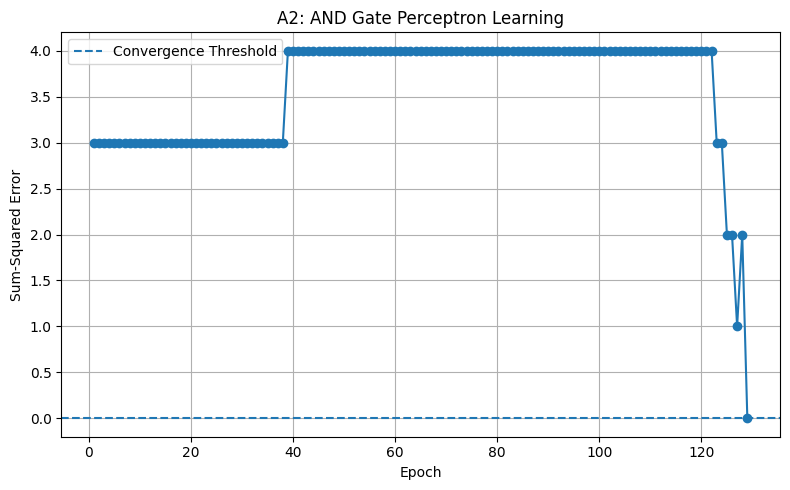


A3: COMPARISON OF ACTIVATION FUNCTIONS

A3 Results


,Activation Function,Epochs,Final SSE,Converged
0,Bipolar Step,1000,3.000000,False
1,Sigmoid,1000,0.041227,False
2,ReLU,383,0.001992,True


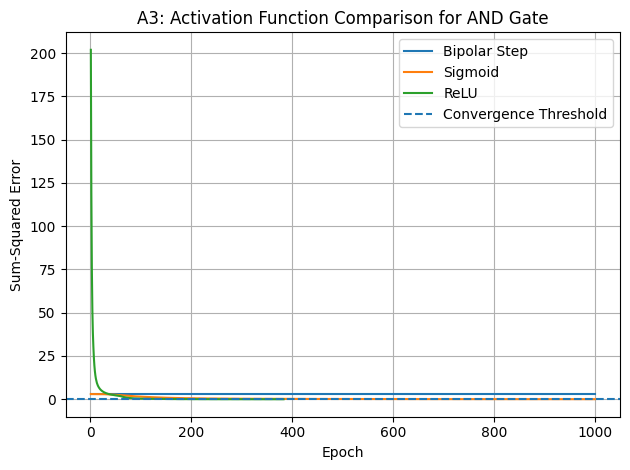


A4: LEARNING RATE COMPARISON


,Learning Rate,Iterations,Final SSE,Converged
0,0.1,67,0.0,True
1,0.2,36,0.0,True
2,0.3,22,0.0,True
3,0.4,22,0.0,True
4,0.5,18,0.0,True
5,0.6,18,0.0,True
6,0.7,14,0.0,True
7,0.8,13,0.0,True
8,0.9,12,0.0,True
9,1.0,11,0.0,True


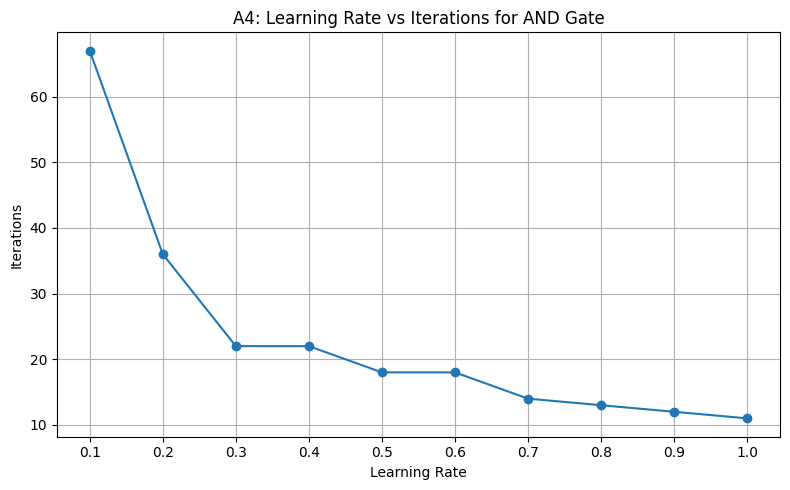


A5: XOR GATE PERCEPTRON
XOR Gate Dataset


,A,B,Target
0,0,0,0
1,0,1,1
2,1,0,1
3,1,1,0



Final Weights [W0, W1, W2]: [ 0.1 -0.1 -0.1]
Epochs Completed: 1000
Final SSE: 3.0
Converged: False

XOR Predictions


,A,B,Target,Prediction
0,0,0,0,1
1,0,1,1,0
2,1,0,1,0
3,1,1,0,0


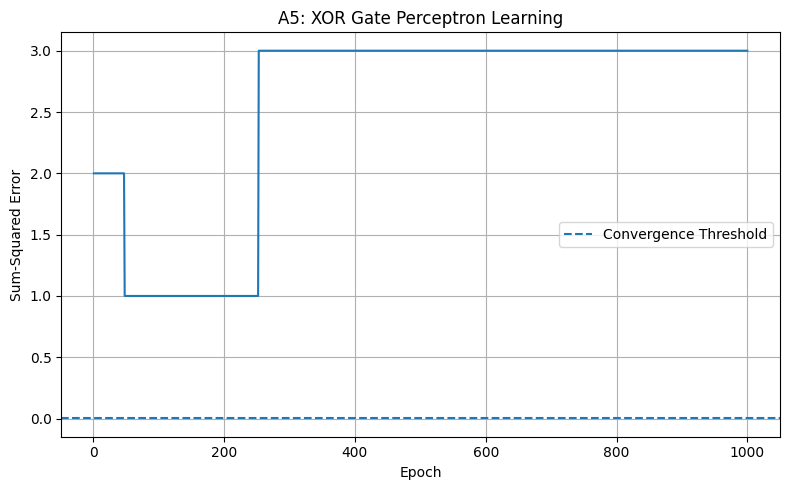


A6: CUSTOMER TRANSACTION CLASSIFICATION
Learning Rate: 0.1
Epochs Completed: 10000
Final Mean Squared Error: 0.000149
Final Weights [Bias, Candies, Mangoes, Milk, Payment]:
[1.7024114  0.03049227 4.16067051 0.35598445 4.73705268]

Customer Classification Results


,Customer,Actual,Predicted Probability,Predicted,Correct
0,C_1,Yes,1.0000,Yes,True
1,C_2,Yes,0.9799,Yes,True
2,C_3,Yes,1.0000,Yes,True
3,C_4,No,0.0000,No,True
4,C_5,Yes,0.9916,Yes,True
5,C_6,No,0.0007,No,True
6,C_7,Yes,0.9855,Yes,True
7,C_8,Yes,0.9879,Yes,True
8,C_9,No,0.0002,No,True
9,C_10,No,0.0257,No,True



Training Accuracy: 1.0


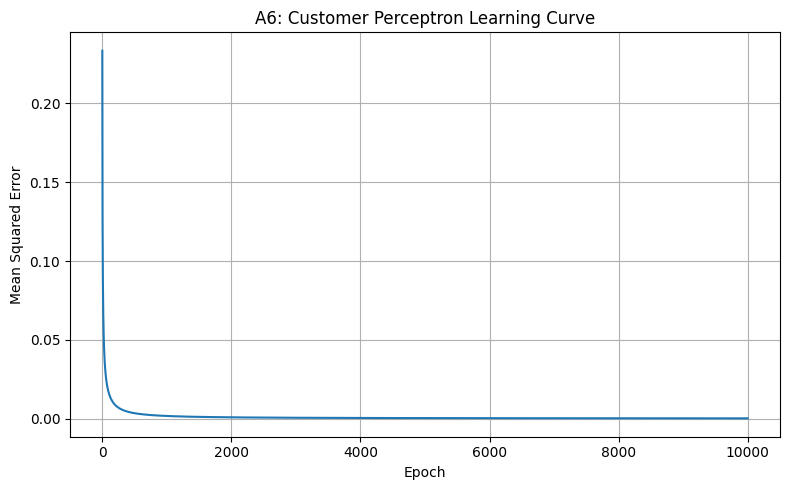


A7: PERCEPTRON VS MATRIX PSEUDO-INVERSE


,Customer,Actual,Perceptron Probability,Perceptron Prediction,Pseudo-Inverse Output,Pseudo-Inverse Prediction
0,C_1,Yes,1.0000,Yes,1.2843,Yes
1,C_2,Yes,0.9799,Yes,0.7450,Yes
2,C_3,Yes,1.0000,Yes,1.1204,Yes
3,C_4,No,0.0000,No,0.0041,No
4,C_5,Yes,0.9916,Yes,0.6692,Yes
5,C_6,No,0.0007,No,0.0457,No
6,C_7,Yes,0.9855,Yes,0.8800,Yes
7,C_8,Yes,0.9879,Yes,0.8097,Yes
8,C_9,No,0.0002,No,0.0318,No
9,C_10,No,0.0257,No,0.4097,No


Perceptron Training Accuracy: 1.0
Pseudo-Inverse Training Accuracy: 1.0

Pseudo-Inverse Weights [Bias, Features]:
[ 0.6        -0.09436819  0.21713405 -0.01342766  0.23416864]

A8: BACKPROPAGATION FOR AND GATE
Learning Rate: 0.05
Epochs Completed: 1000
Final SSE: 0.7317849538451257
Converged: False

Hidden Layer Weights:
[[ 0.30937187 -0.02966243  0.33885611]
 [-0.07132077 -0.66130955  0.44180537]]

Output Layer Weights:
[[ 0.16631344 -0.47722326 -0.93998686]]

AND Gate Results


,A,B,Target,Output Probability,Prediction
0,0,0,0,0.2435,0
1,0,1,0,0.2580,0
2,1,0,0,0.2473,0
3,1,1,1,0.2619,0


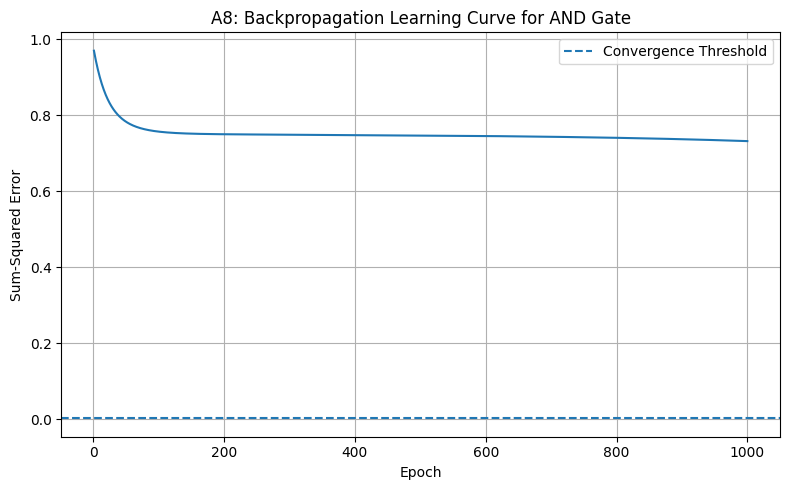


A9: BACKPROPAGATION FOR XOR GATE
Learning Rate: 0.05
Epochs Completed: 1000
Final SSE: 1.0002975945978396
Converged: False

Hidden Layer Weights:
[[ 0.25624127 -0.04161682  0.34823744]
 [ 0.1480416  -0.40314416  0.45350412]]

Output Layer Weights:
[[ 0.27202092  0.27656022 -0.32847056]]

XOR Gate Results


,A,B,Target,Output Probability,Prediction
0,0,0,0,0.5000,1
1,0,1,1,0.4925,0
2,1,0,1,0.5065,1
3,1,1,0,0.4992,0


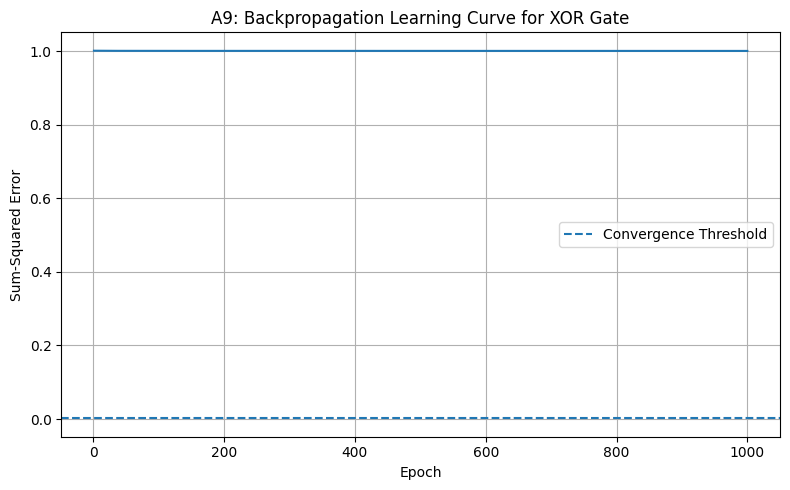


A10: TWO-OUTPUT-NODE NETWORK
Learning Rate: 0.05
Epochs Completed: 1000
Final SSE: 0.9256655295943702
Converged: False

Hidden Layer Weights:
[[-1.06201813 -1.19242773  0.65664503]
 [-1.31571114 -1.66027286  1.23034257]]

Output Layer Weights:
[[ 1.30505921  1.89617108 -0.29125899]
 [-1.18834605 -1.83732799  0.22007663]]

AND Gate Results


,A,B,Target Encoding,Predicted Output,Predicted Encoding,Correct
0,0,0,"[1, 0]","[0.8845, 0.1209]","[1, 0]",True
1,0,1,"[1, 0]","[0.7187, 0.2803]","[1, 0]",True
2,1,0,"[1, 0]","[0.7574, 0.2433]","[1, 0]",True
3,1,1,"[0, 1]","[0.5523, 0.4371]","[1, 0]",False


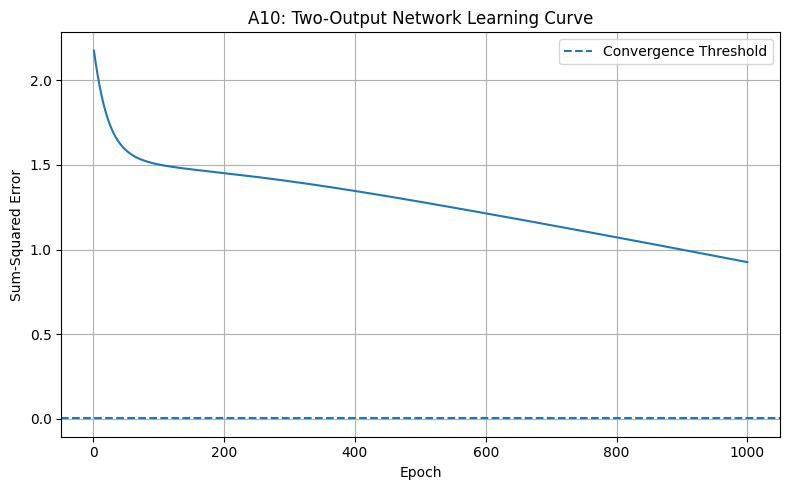


A11: MLPCLASSIFIER FOR AND AND XOR


,Gate,Accuracy,Targets,Predictions,Correct
0,AND,1.0,"[0, 0, 0, 1]","[0, 0, 0, 1]",True
1,XOR,1.0,"[0, 1, 1, 0]","[0, 1, 1, 0]",True



AND Gate
Predictions: [0 0 0 1]
Expected: [0, 0, 0, 1]
Probabilities:


,Class 0,Class 1
0,0.9999,0.0001
1,0.9996,0.0004
2,0.9995,0.0005
3,0.0012,0.9988



XOR Gate
Predictions: [0 1 1 0]
Expected: [0, 1, 1, 0]
Probabilities:


,Class 0,Class 1
0,0.9987,0.0013
1,0.0011,0.9989
2,0.0011,0.9989
3,0.9988,0.0012


Dataset shape: (200, 256)
Total loaded images: 200
Missing or unreadable images: 0
Benign images: 100
Malignant images: 100


In [ ]:
# Main Program

print("=" * 50)
print("A1: PERCEPTRON BUILDING BLOCKS")
print("=" * 50)

inputs_a1 = [1, 0]
weights_a1 = [0.5, 0.2, -0.4]

net_input_a1 = summation_unit(inputs_a1, weights_a1)

print("\nSummation Unit Output:", net_input_a1)
print("\nActivation Function Outputs:")
print("Step:", step_activation(net_input_a1))
print("Bipolar Step:", bipolar_step_activation(net_input_a1))
print("Sigmoid:", sigmoid_activation(net_input_a1))
print("TanH:", tanh_activation(net_input_a1))
print("ReLU:", relu_activation(net_input_a1))
print("Leaky ReLU:", leaky_relu_activation(net_input_a1))

target_a1 = 1
prediction_a1 = step_activation(net_input_a1)
error_a1 = error_comparator(target_a1, prediction_a1)

print("\nComparator Unit")
print("Target:", target_a1)
print("Predicted Output:", prediction_a1)
print("Error:", error_a1)
print("Squared Error:", error_a1 ** 2)


print("\n" + "=" * 50)
print("A2: AND GATE PERCEPTRON")
print("=" * 50)

weights_a2, epochs_a2, errors_a2, X_and, y_and = train_perceptron_and(
    learning_rate=LEARNING_RATE,
    max_epochs=MAX_EPOCHS,
    convergence_error=CONVERGENCE_ERROR
)

predictions_a2 = np.array([
    step_activation(summation_unit(inputs, weights_a2))
    for inputs in X_and
])

print("Initial Weights: [10.0, 0.2, -0.75]")
print("Learning Rate:", LEARNING_RATE)
print("Final Weights [W0, W1, W2]:", weights_a2)
print("Epochs Completed:", epochs_a2)
print("Final SSE:", errors_a2[-1])
print("Converged:", errors_a2[-1] <= CONVERGENCE_ERROR)

print("\nAND Gate Prediction Results")
display(pd.DataFrame({
    "A": X_and[:, 0].astype(int),
    "B": X_and[:, 1].astype(int),
    "Target": y_and,
    "Prediction": predictions_a2
}))

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(errors_a2) + 1),
    errors_a2,
    marker="o"
)
plt.axhline(
    y=CONVERGENCE_ERROR,
    linestyle="--",
    label="Convergence Threshold"
)
plt.xlabel("Epoch")
plt.ylabel("Sum-Squared Error")
plt.title("A2: AND Gate Perceptron Learning")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



print("\n" + "=" * 50)
print("A3: COMPARISON OF ACTIVATION FUNCTIONS")
print("=" * 50)

activation_functions = {
    "Bipolar Step": bipolar_step_activation,
    "Sigmoid": sigmoid_activation,
    "ReLU": relu_activation
}

a3_results = []

for activation_name, activation_func in activation_functions.items():
    final_weights, epochs, errors, X_data, y_data = (
        train_perceptron_activation(
            X_and,
            y_and,
            activation=activation_func,
            learning_rate=LEARNING_RATE,
            max_epochs=MAX_EPOCHS,
            convergence_error=CONVERGENCE_ERROR
        )
    )

    a3_results.append({
        "Activation Function": activation_name,
        "Epochs": epochs,
        "Final SSE": errors[-1],
        "Converged": errors[-1] <= CONVERGENCE_ERROR
    })

    plt.plot(
        range(1, len(errors) + 1),
        errors,
        label=activation_name
    )

print("\nA3 Results")
display(pd.DataFrame(a3_results))

plt.axhline(
    y=CONVERGENCE_ERROR,
    linestyle="--",
    label="Convergence Threshold"
)
plt.xlabel("Epoch")
plt.ylabel("Sum-Squared Error")
plt.title("A3: Activation Function Comparison for AND Gate")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



print("\n" + "=" * 50)
print("A4: LEARNING RATE COMPARISON")
print("=" * 50)

a4_results = compare_learning_rates(
    X_and,
    y_and,
    learning_rates=np.arange(0.1, 1.01, 0.1),
    max_epochs=MAX_EPOCHS,
    convergence_error=CONVERGENCE_ERROR
)

display(a4_results)

plt.figure(figsize=(8, 5))
plt.plot(
    a4_results["Learning Rate"],
    a4_results["Iterations"],
    marker="o"
)
plt.xlabel("Learning Rate")
plt.ylabel("Iterations")
plt.title("A4: Learning Rate vs Iterations for AND Gate")
plt.xticks(np.arange(0.1, 1.01, 0.1))
plt.grid(True)
plt.tight_layout()
plt.show()



print("\n" + "=" * 50)
print("A5: XOR GATE PERCEPTRON")
print("=" * 50)

X_xor, y_xor = get_xor_dataset()

print("XOR Gate Dataset")
display(pd.DataFrame({
    "A": X_xor[:, 0].astype(int),
    "B": X_xor[:, 1].astype(int),
    "Target": y_xor
}))

weights_xor, epochs_xor, errors_xor, _, _ = train_perceptron_and(
    learning_rate=LEARNING_RATE,
    max_epochs=MAX_EPOCHS,
    convergence_error=CONVERGENCE_ERROR
) if False else (None, None, None, None, None)

weights_xor = np.array([10.0, 0.2, -0.75])
xor_errors = []

for epoch in range(1, MAX_EPOCHS + 1):
    for inputs, target in zip(X_xor, y_xor):
        prediction = step_activation(summation_unit(inputs, weights_xor))
        error = target - prediction

        weights_xor[0] += LEARNING_RATE * error
        weights_xor[1:] += LEARNING_RATE * error * inputs

    predictions = np.array([
        step_activation(summation_unit(inputs, weights_xor))
        for inputs in X_xor
    ])

    sse = float(np.sum((y_xor - predictions) ** 2))
    xor_errors.append(sse)

    if sse <= CONVERGENCE_ERROR:
        break

predictions_xor = np.array([
    step_activation(summation_unit(inputs, weights_xor))
    for inputs in X_xor
])

print("\nFinal Weights [W0, W1, W2]:", weights_xor)
print("Epochs Completed:", epoch)
print("Final SSE:", xor_errors[-1])
print("Converged:", xor_errors[-1] <= CONVERGENCE_ERROR)

print("\nXOR Predictions")
display(pd.DataFrame({
    "A": X_xor[:, 0].astype(int),
    "B": X_xor[:, 1].astype(int),
    "Target": y_xor,
    "Prediction": predictions_xor
}))

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(xor_errors) + 1), xor_errors)
plt.axhline(
    y=CONVERGENCE_ERROR,
    linestyle="--",
    label="Convergence Threshold"
)
plt.xlabel("Epoch")
plt.ylabel("Sum-Squared Error")
plt.title("A5: XOR Gate Perceptron Learning")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



print("\n" + "=" * 50)
print("A6: CUSTOMER TRANSACTION CLASSIFICATION")
print("=" * 50)

(
    X_customers,
    y_customers,
    customer_probabilities,
    customer_predictions,
    customer_weights,
    customer_scaler,
    customer_errors,
    customer_epochs
) = train_customer_perceptron()

customer_names = [f"C_{i}" for i in range(1, 11)]

print("Learning Rate: 0.1")
print("Epochs Completed:", customer_epochs)
print("Final Mean Squared Error:", round(customer_errors[-1], 6))
print("Final Weights [Bias, Candies, Mangoes, Milk, Payment]:")
print(customer_weights)

print("\nCustomer Classification Results")
display(pd.DataFrame({
    "Customer": customer_names,
    "Actual": np.where(y_customers == 1, "Yes", "No"),
    "Predicted Probability": customer_probabilities.round(4),
    "Predicted": np.where(customer_predictions == 1, "Yes", "No"),
    "Correct": customer_predictions == y_customers
}))

print(
    "\nTraining Accuracy:",
    round(accuracy_score(y_customers, customer_predictions), 4)
)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(customer_errors) + 1), customer_errors)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("A6: Customer Perceptron Learning Curve")
plt.grid(True)
plt.tight_layout()
plt.show()




print("\n" + "=" * 50)
print("A7: PERCEPTRON VS MATRIX PSEUDO-INVERSE")
print("=" * 50)

pseudo_weights, pseudo_outputs, pseudo_predictions = compare_pseudoinverse(
    X_customers,
    y_customers
)

comparison_df = pd.DataFrame({
    "Customer": customer_names,
    "Actual": np.where(y_customers == 1, "Yes", "No"),
    "Perceptron Probability": customer_probabilities.round(4),
    "Perceptron Prediction": np.where(
        customer_predictions == 1, "Yes", "No"
    ),
    "Pseudo-Inverse Output": pseudo_outputs.round(4),
    "Pseudo-Inverse Prediction": np.where(
        pseudo_predictions == 1, "Yes", "No"
    )
})

display(comparison_df)

print("Perceptron Training Accuracy:",
      round(accuracy_score(y_customers, customer_predictions), 4))

print("Pseudo-Inverse Training Accuracy:",
      round(accuracy_score(y_customers, pseudo_predictions), 4))

print("\nPseudo-Inverse Weights [Bias, Features]:")
print(pseudo_weights)




print("\n" + "=" * 50)
print("A8: BACKPROPAGATION FOR AND GATE")
print("=" * 50)

(
    hidden_weights_a8,
    output_weights_a8,
    epochs_a8,
    errors_a8,
    X_a8,
    y_a8,
    predictions_a8
) = train_and_backpropagation(
    learning_rate=LEARNING_RATE,
    max_epochs=MAX_EPOCHS,
    convergence_error=CONVERGENCE_ERROR
)

predicted_classes_a8 = (predictions_a8 >= 0.5).astype(int)

print("Learning Rate:", LEARNING_RATE)
print("Epochs Completed:", epochs_a8)
print("Final SSE:", errors_a8[-1])
print("Converged:", errors_a8[-1] <= CONVERGENCE_ERROR)
print("\nHidden Layer Weights:")
print(hidden_weights_a8)
print("\nOutput Layer Weights:")
print(output_weights_a8)

print("\nAND Gate Results")
display(pd.DataFrame({
    "A": X_a8[:, 0].astype(int),
    "B": X_a8[:, 1].astype(int),
    "Target": y_a8.astype(int),
    "Output Probability": predictions_a8.round(4),
    "Prediction": predicted_classes_a8
}))

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(errors_a8) + 1), errors_a8)
plt.axhline(
    y=CONVERGENCE_ERROR,
    linestyle="--",
    label="Convergence Threshold"
)
plt.xlabel("Epoch")
plt.ylabel("Sum-Squared Error")
plt.title("A8: Backpropagation Learning Curve for AND Gate")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



print("\n" + "=" * 50)
print("A9: BACKPROPAGATION FOR XOR GATE")
print("=" * 50)

(
    hidden_weights_a9,
    output_weights_a9,
    epochs_a9,
    errors_a9,
    X_a9,
    y_a9,
    predictions_a9
) = train_xor_backpropagation(
    learning_rate=LEARNING_RATE,
    max_epochs=MAX_EPOCHS,
    convergence_error=CONVERGENCE_ERROR
)

predicted_classes_a9 = (predictions_a9 >= 0.5).astype(int)

print("Learning Rate:", LEARNING_RATE)
print("Epochs Completed:", epochs_a9)
print("Final SSE:", errors_a9[-1])
print("Converged:", errors_a9[-1] <= CONVERGENCE_ERROR)

print("\nHidden Layer Weights:")
print(hidden_weights_a9)

print("\nOutput Layer Weights:")
print(output_weights_a9)

print("\nXOR Gate Results")
display(pd.DataFrame({
    "A": X_a9[:, 0].astype(int),
    "B": X_a9[:, 1].astype(int),
    "Target": y_a9.astype(int),
    "Output Probability": predictions_a9.round(4),
    "Prediction": predicted_classes_a9
}))

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(errors_a9) + 1), errors_a9)
plt.axhline(
    y=CONVERGENCE_ERROR,
    linestyle="--",
    label="Convergence Threshold"
)
plt.xlabel("Epoch")
plt.ylabel("Sum-Squared Error")
plt.title("A9: Backpropagation Learning Curve for XOR Gate")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


print("\n" + "=" * 50)
print("A10: TWO-OUTPUT-NODE NETWORK")
print("=" * 50)

(
    hidden_weights_a10,
    output_weights_a10,
    epochs_a10,
    errors_a10,
    X_a10,
    y_a10,
    outputs_a10
) = train_two_output_network(
    learning_rate=LEARNING_RATE,
    max_epochs=MAX_EPOCHS,
    convergence_error=CONVERGENCE_ERROR
)

predicted_classes_a10 = np.argmax(outputs_a10, axis=1)
target_classes_a10 = np.argmax(y_a10, axis=1)

print("Learning Rate:", LEARNING_RATE)
print("Epochs Completed:", epochs_a10)
print("Final SSE:", errors_a10[-1])
print("Converged:", errors_a10[-1] <= CONVERGENCE_ERROR)

print("\nHidden Layer Weights:")
print(hidden_weights_a10)

print("\nOutput Layer Weights:")
print(output_weights_a10)

print("\nAND Gate Results")
display(pd.DataFrame({
    "A": X_a10[:, 0].astype(int),
    "B": X_a10[:, 1].astype(int),
    "Target Encoding": [row.tolist() for row in y_a10.astype(int)],
    "Predicted Output": [row.round(4).tolist() for row in outputs_a10],
    "Predicted Encoding": [
        [1, 0] if value == 0 else [0, 1]
        for value in predicted_classes_a10
    ],
    "Correct": predicted_classes_a10 == target_classes_a10
}))

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(errors_a10) + 1), errors_a10)
plt.axhline(
    y=CONVERGENCE_ERROR,
    linestyle="--",
    label="Convergence Threshold"
)
plt.xlabel("Epoch")
plt.ylabel("Sum-Squared Error")
plt.title("A10: Two-Output Network Learning Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


print("\n" + "=" * 50)
print("A11: MLPCLASSIFIER FOR AND AND XOR")
print("=" * 50)

results_a11, mlp_gate_models = run_mlp_logic_gates()

display(results_a11)

X_logic = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

for gate_name, model in mlp_gate_models.items():
    print(f"\n{gate_name} Gate")
    print("Predictions:", model.predict(X_logic))
    print("Expected:", [0, 0, 0, 1] if gate_name == "AND" else [0, 1, 1, 0])
    print("Probabilities:")
    display(pd.DataFrame(
        model.predict_proba(X_logic).round(4),
        columns=[f"Class {c}" for c in model.classes_]
    ))



    project_subset = (
    metadata.groupby("label", group_keys=False)
    .sample(n=100, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

X_project, y_project, missing_files = load_project_dataset(project_subset)

print("Dataset shape:", X_project.shape)
print("Total loaded images:", len(y_project))
print("Missing or unreadable images:", missing_files)
print("Benign images:", np.sum(y_project == 0))
print("Malignant images:", np.sum(y_project == 1))

if len(y_project) != 200:
    raise ValueError(
        "Expected 200 images. Check the dataset paths and missing files."
    )